# Multipath Channel and Frequency-Domain Equalization

## Objective

This notebook extends the QPSK/OFDM transmitter developed previously by introducing a frequency-selective multipath wireless channel.

The goals are to:

1. Build a reproducible QPSK/OFDM transmitter with a cyclic prefix.
2. Model a complex baseband multipath channel with several delayed signal paths.
3. Examine the channel impulse response and frequency response.
4. Observe how multipath distorts the received QPSK subcarrier symbols.
5. Apply frequency-domain zero-forcing equalization using known channel coefficients.
6. Compare the received constellation before and after equalization.
7. Measure bit recovery and bit error rate under ideal multipath conditions.

This experiment assumes perfect knowledge of the channel response so that the effect of equalization can be studied directly. Noise and practical channel estimation will be introduced in later experiments.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducible random-number generator
rng = np.random.default_rng(42)

# OFDM parameters
N_fft = 64
N_cp = 16

# Choose a bit count that exactly fills complete OFDM symbols
num_bits = 4096

# Generate binary data
bits = rng.integers(
    low=0,
    high=2,
    size=num_bits
)

# Group bits into QPSK bit pairs
bit_pairs = bits.reshape(-1, 2)

# Gray-coded normalized QPSK mapping
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Organize QPSK symbols into OFDM frequency-domain blocks
ofdm_frequency_symbols = qpsk_symbols.reshape(-1, N_fft)

# Convert each OFDM symbol to the time domain
ofdm_time_symbols = np.fft.ifft(
    ofdm_frequency_symbols,
    axis=1
)

# Add cyclic prefix
cyclic_prefix = ofdm_time_symbols[:, -N_cp:]

ofdm_with_cp = np.concatenate(
    (cyclic_prefix, ofdm_time_symbols),
    axis=1
)

# Serialize the OFDM blocks into one transmitted waveform
tx_serial = ofdm_with_cp.reshape(-1)

print("Number of bits:", len(bits))
print("Number of QPSK symbols:", len(qpsk_symbols))
print("Number of OFDM symbols:", ofdm_frequency_symbols.shape[0])
print("Useful OFDM symbol length:", N_fft)
print("Cyclic-prefix length:", N_cp)
print("Transmitted block length:", ofdm_with_cp.shape[1])
print("Total transmitted samples:", len(tx_serial))

Number of bits: 4096
Number of QPSK symbols: 2048
Number of OFDM symbols: 32
Useful OFDM symbol length: 64
Cyclic-prefix length: 16
Transmitted block length: 80
Total transmitted samples: 2560


## Multipath Channel Model

In a wireless environment, the receiver may observe several copies of the transmitted signal caused by reflections from objects in the environment.

A discrete-time multipath channel can be represented by the impulse response

$$
h[\ell],
$$

and the received signal is the linear convolution

$$
y[n]
=
\sum_{\ell=0}^{L_h-1}
h[\ell]x[n-\ell].
$$

Each nonzero channel coefficient represents one propagation path with its own attenuation, phase shift, and delay.

This experiment uses three paths:

- a direct path at delay 0,
- a reflected path at delay 3 samples,
- a weaker reflected path at delay 8 samples.

Because the maximum channel delay is 8 samples and the cyclic prefix contains 16 samples, the cyclic prefix is long enough for this channel:

$$
N_{\mathrm{CP}} \ge L_h-1.
$$

In [2]:
# Three-path complex baseband multipath channel
h = np.zeros(9, dtype=complex)

h[0] = 1.0
h[3] = 0.45 * np.exp(1j * 0.6)
h[8] = 0.25 * np.exp(-1j * 0.9)

# Normalize total channel energy
h = h / np.sqrt(np.sum(np.abs(h) ** 2))

channel_energy = np.sum(np.abs(h) ** 2)
max_channel_delay = len(h) - 1

print("Channel impulse-response length:", len(h))
print("Maximum channel delay:", max_channel_delay, "samples")
print("Cyclic-prefix length:", N_cp, "samples")
print("Normalized channel energy:", channel_energy)
print("CP condition satisfied:", N_cp >= max_channel_delay)

assert N_cp >= max_channel_delay

Channel impulse-response length: 9
Maximum channel delay: 8 samples
Cyclic-prefix length: 16 samples
Normalized channel energy: 0.9999999999999996
CP condition satisfied: True


## Channel Impulse Response

The impulse response shows the strength and delay of each propagation path.

Only three taps are nonzero in this model. The direct path arrives first, while the reflected paths arrive several samples later with smaller amplitudes.

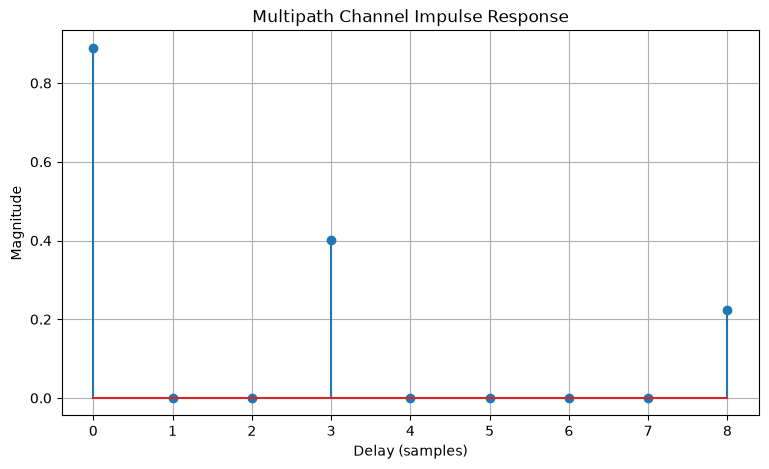

In [3]:
delay_samples = np.arange(len(h))

plt.figure(figsize=(9, 5))

plt.stem(
    delay_samples,
    np.abs(h)
)

plt.xlabel("Delay (samples)")
plt.ylabel("Magnitude")
plt.title("Multipath Channel Impulse Response")
plt.grid(True)

plt.savefig(
    "../results/multipath_impulse_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Channel Frequency Response

The multipath impulse response describes the channel in the time domain. OFDM is especially useful because the same channel can be viewed independently across its frequency-domain subcarriers.

The discrete Fourier transform of the channel impulse response is

$$
H[k]
=
\sum_{\ell=0}^{L_h-1}
h[\ell]e^{-j2\pi k\ell/N},
$$

where $H[k]$ is the complex channel gain seen by subcarrier $k$.

Because the delayed propagation paths combine constructively at some frequencies and destructively at others, the magnitude of $H[k]$ is not constant across the OFDM band. This is known as a frequency-selective channel.

The following calculation evaluates the channel response at the same 64 frequency bins used by the OFDM system.

In [4]:
# Evaluate the multipath channel at the 64 OFDM subcarriers
H = np.fft.fft(h, n=N_fft)

subcarrier_indices = np.arange(N_fft)
H_magnitude = np.abs(H)

print("Number of channel frequency bins:", len(H))
print("Minimum channel magnitude:", np.min(H_magnitude))
print("Maximum channel magnitude:", np.max(H_magnitude))
print("Weakest subcarrier index:", np.argmin(H_magnitude))
print("Strongest subcarrier index:", np.argmax(H_magnitude))

Number of channel frequency bins: 64
Minimum channel magnitude: 0.31562687431678127
Maximum channel magnitude: 1.5077557153194916
Weakest subcarrier index: 35
Strongest subcarrier index: 23


## Frequency-Selective Fading

The magnitude response shows how strongly the channel attenuates or amplifies each OFDM subcarrier.

For a flat channel, all subcarriers would experience approximately the same gain. In this multipath channel, however, the response varies substantially with frequency because the delayed paths interfere differently at different subcarriers.

The magnitude is plotted in decibels using

$$
20\log_{10}|H[k]|.
$$

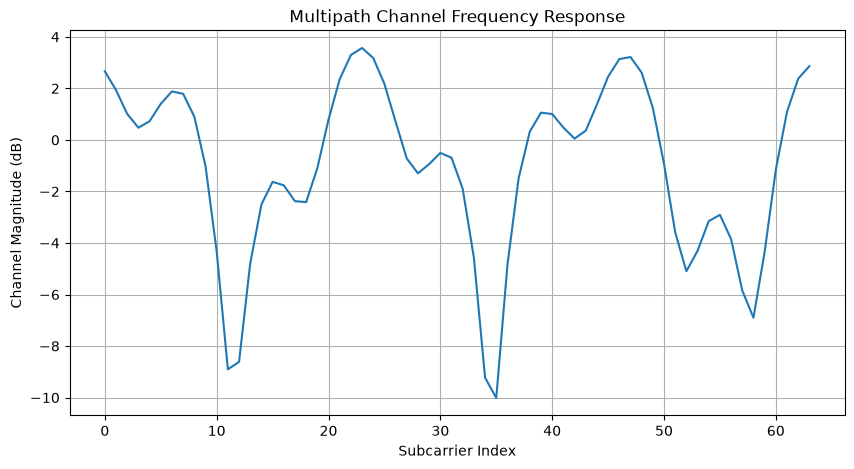

In [5]:
H_magnitude_db = 20 * np.log10(np.maximum(H_magnitude, 1e-12))

plt.figure(figsize=(10, 5))

plt.plot(
    subcarrier_indices,
    H_magnitude_db
)

plt.xlabel("Subcarrier Index")
plt.ylabel("Channel Magnitude (dB)")
plt.title("Multipath Channel Frequency Response")
plt.grid(True)

plt.savefig(
    "../results/multipath_frequency_response.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
print(
    "Minimum channel magnitude (linear):",
    f"{np.min(H_magnitude):.4f}"
)

print(
    "Maximum channel magnitude (linear):",
    f"{np.max(H_magnitude):.4f}"
)

print(
    "Minimum channel magnitude (dB):",
    f"{np.min(H_magnitude_db):.2f} dB"
)

print(
    "Maximum channel magnitude (dB):",
    f"{np.max(H_magnitude_db):.2f} dB"
)

Minimum channel magnitude (linear): 0.3156
Maximum channel magnitude (linear): 1.5078
Minimum channel magnitude (dB): -10.02 dB
Maximum channel magnitude (dB): 3.57 dB


## Passing the OFDM Signal Through the Multipath Channel

The transmitted OFDM waveform now passes through the multipath channel.

For a discrete-time channel with impulse response $h[\ell]$, the received signal is the linear convolution

$$
y[n]
=
\sum_{\ell=0}^{L_h-1}
h[\ell]x[n-\ell].
$$

Each delayed path therefore contributes a shifted, attenuated, and phase-rotated copy of the transmitted waveform.

The cyclic prefix is longer than the maximum channel delay in this experiment. After the cyclic prefix is removed at the receiver, the useful portion of each OFDM symbol can therefore be treated as a circular convolution with the channel. In the frequency domain, this becomes

$$
Y[k] = H[k]X[k].
$$

This relationship is the key reason that OFDM allows a frequency-selective channel to be corrected independently on each subcarrier.

In [7]:
# Pass the serialized OFDM waveform through the multipath channel
rx_serial_full = np.convolve(
    tx_serial,
    h,
    mode="full"
)

# Keep the samples corresponding to the transmitted OFDM stream.
# The remaining samples are only the final channel tail.
rx_serial = rx_serial_full[:len(tx_serial)]

num_ofdm_symbols = ofdm_frequency_symbols.shape[0]
block_length = N_fft + N_cp

print("Transmitted samples:", len(tx_serial))
print("Full convolution samples:", len(rx_serial_full))
print("Received samples retained:", len(rx_serial))
print("OFDM symbols:", num_ofdm_symbols)
print("Samples per transmitted OFDM block:", block_length)

Transmitted samples: 2560
Full convolution samples: 2568
Received samples retained: 2560
OFDM symbols: 32
Samples per transmitted OFDM block: 80


## Receiver Processing Before Equalization

The receiver first separates the received waveform back into OFDM blocks.

Each transmitted block contains 64 useful samples and a 16-sample cyclic prefix, for a total of 80 samples.

The receiver removes the cyclic prefix and applies a 64-point FFT to each useful OFDM symbol. This converts the signal back into the frequency domain.

Because the signal has passed through the multipath channel but has not yet been equalized, the received subcarrier symbols should satisfy

$$
Y[k] = H[k]X[k].
$$

In [8]:
# Reshape the received serial waveform into OFDM blocks
received_blocks = rx_serial.reshape(
    num_ofdm_symbols,
    block_length
)

# Remove the cyclic prefix
received_without_cp = received_blocks[:, N_cp:]

# Convert the received OFDM symbols back to the frequency domain
received_frequency_symbols = np.fft.fft(
    received_without_cp,
    axis=1
)

print("Received block array shape:", received_blocks.shape)
print("Shape after CP removal:", received_without_cp.shape)
print(
    "Received frequency-domain shape:",
    received_frequency_symbols.shape
)

Received block array shape: (32, 80)
Shape after CP removal: (32, 64)
Received frequency-domain shape: (32, 64)


In [9]:
# Theoretical frequency-domain result: Y[k] = H[k] X[k]
expected_received_symbols = (
    ofdm_frequency_symbols * H[np.newaxis, :]
)

channel_model_error = np.max(
    np.abs(
        received_frequency_symbols
        - expected_received_symbols
    )
)

print(
    "Maximum error between simulated and theoretical Y[k] = H[k]X[k]:",
    f"{channel_model_error:.3e}"
)

assert np.allclose(
    received_frequency_symbols,
    expected_received_symbols,
    atol=1e-12
)

Maximum error between simulated and theoretical Y[k] = H[k]X[k]: 7.109e-16


## Received Constellation Before Equalization

In the ideal QPSK transmitter, every symbol belongs to one of four constellation points.

After passing through the multipath channel, each OFDM subcarrier is multiplied by a different complex channel coefficient $H[k]$.

Therefore, the received symbol is

$$
Y[k] = H[k]X[k].
$$

The magnitude of $H[k]$ changes the symbol amplitude, while its phase rotates the symbol in the complex plane.

Because the channel response varies from one subcarrier to another, the four ideal QPSK points spread into many different received locations. This distortion occurs even though no additive noise has been introduced yet.

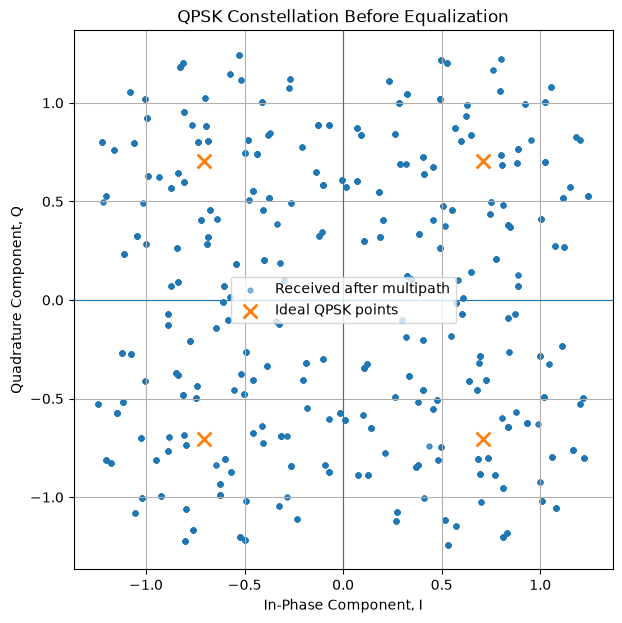

In [10]:
received_symbols_before_eq = received_frequency_symbols.reshape(-1)

# Ideal normalized QPSK points for reference
ideal_qpsk_points = np.array([
    1 + 1j,
    1 - 1j,
    -1 + 1j,
    -1 - 1j
]) / np.sqrt(2)

plt.figure(figsize=(7, 7))

plt.scatter(
    received_symbols_before_eq.real,
    received_symbols_before_eq.imag,
    s=12,
    alpha=0.5,
    label="Received after multipath"
)

plt.scatter(
    ideal_qpsk_points.real,
    ideal_qpsk_points.imag,
    marker="x",
    s=100,
    linewidths=2,
    label="Ideal QPSK points"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("In-Phase Component, I")
plt.ylabel("Quadrature Component, Q")
plt.title("QPSK Constellation Before Equalization")
plt.grid(True)
plt.legend()
plt.gca().set_aspect("equal", adjustable="box")

plt.savefig(
    "../results/constellation_before_equalization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
normalized_symbol_error_before_eq = np.sqrt(
    np.mean(
        np.abs(
            received_frequency_symbols
            - ofdm_frequency_symbols
        ) ** 2
    )
    /
    np.mean(
        np.abs(ofdm_frequency_symbols) ** 2
    )
)

print(
    "Normalized RMS symbol error before equalization:",
    f"{100 * normalized_symbol_error_before_eq:.2f}%"
)

Normalized RMS symbol error before equalization: 47.09%


## Zero-Forcing Frequency-Domain Equalization

After cyclic-prefix removal and the FFT, each received OFDM subcarrier satisfies

$$
Y[k] = H[k]X[k].
$$

If the channel response $H[k]$ is known, its effect can be removed independently on each subcarrier.

A zero-forcing equalizer uses

$$
G_{\mathrm{ZF}}[k] = \frac{1}{H[k]},
$$

so that the equalized symbol estimate is

$$
\hat{X}[k]
=
G_{\mathrm{ZF}}[k]Y[k]
=
\frac{Y[k]}{H[k]}.
$$

Under the current ideal conditions, with no additive noise and no zero-valued channel coefficients, this should recover the transmitted QPSK symbols to within numerical floating-point precision.

Zero-forcing equalization can amplify noise when $|H[k]|$ is very small. That effect will become important when noise is introduced in a later experiment.

In [12]:
# Verify that no channel coefficient is effectively zero
minimum_channel_gain = np.min(np.abs(H))

print(
    "Minimum channel magnitude:",
    f"{minimum_channel_gain:.4f}"
)

assert minimum_channel_gain > 1e-12

# Zero-forcing frequency-domain equalizer
zf_equalizer = 1 / H

# Apply the equalizer independently to every subcarrier
equalized_frequency_symbols = (
    received_frequency_symbols
    * zf_equalizer[np.newaxis, :]
)

print(
    "Equalized frequency-domain shape:",
    equalized_frequency_symbols.shape
)

Minimum channel magnitude: 0.3156
Equalized frequency-domain shape: (32, 64)


In [13]:
# Compare the equalized symbols with the originally transmitted symbols
max_symbol_error_after_eq = np.max(
    np.abs(
        equalized_frequency_symbols
        - ofdm_frequency_symbols
    )
)

normalized_symbol_error_after_eq = np.sqrt(
    np.mean(
        np.abs(
            equalized_frequency_symbols
            - ofdm_frequency_symbols
        ) ** 2
    )
    /
    np.mean(
        np.abs(ofdm_frequency_symbols) ** 2
    )
)

print(
    "Maximum symbol reconstruction error after equalization:",
    f"{max_symbol_error_after_eq:.3e}"
)

print(
    "Normalized RMS symbol error before equalization:",
    f"{100 * normalized_symbol_error_before_eq:.2f}%"
)

print(
    "Normalized RMS symbol error after equalization:",
    f"{100 * normalized_symbol_error_after_eq:.3e}%"
)

assert np.allclose(
    equalized_frequency_symbols,
    ofdm_frequency_symbols,
    atol=1e-12
)

Maximum symbol reconstruction error after equalization: 1.159e-15
Normalized RMS symbol error before equalization: 47.09%
Normalized RMS symbol error after equalization: 3.064e-14%


## Constellation After Equalization

Before equalization, the frequency-selective channel changed both the magnitude and phase of the QPSK symbols, spreading the received constellation away from the four ideal points.

The zero-forcing equalizer compensates for the complex gain of each subcarrier:

$$
\hat{X}[k] = \frac{Y[k]}{H[k]}.
$$

Because no additive noise is present in this experiment and the channel response is known exactly, the equalized constellation should collapse back onto the four ideal QPSK constellation points.

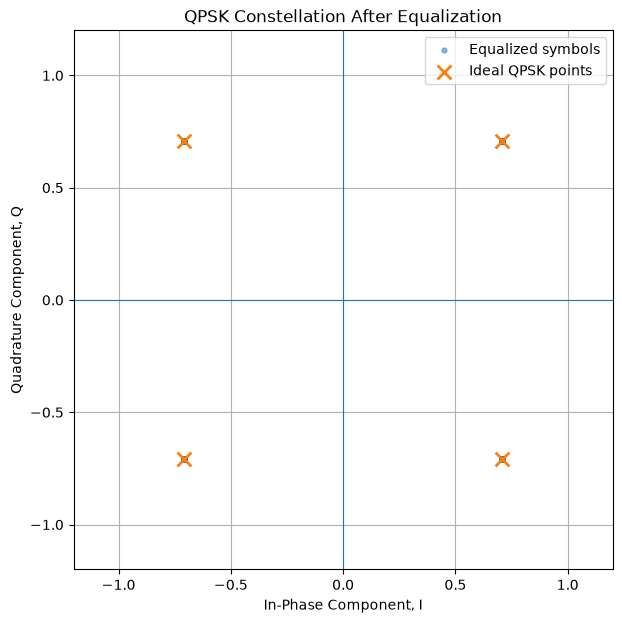

In [14]:
equalized_symbols = equalized_frequency_symbols.reshape(-1)

plt.figure(figsize=(7, 7))

plt.scatter(
    equalized_symbols.real,
    equalized_symbols.imag,
    s=12,
    alpha=0.5,
    label="Equalized symbols"
)

plt.scatter(
    ideal_qpsk_points.real,
    ideal_qpsk_points.imag,
    marker="x",
    s=100,
    linewidths=2,
    label="Ideal QPSK points"
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("In-Phase Component, I")
plt.ylabel("Quadrature Component, Q")
plt.title("QPSK Constellation After Equalization")

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)

plt.grid(True)
plt.legend()
plt.gca().set_aspect("equal", adjustable="box")

plt.savefig(
    "../results/constellation_after_equalization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Bit Recovery and BER Comparison

The constellation plots show that the multipath channel substantially changes the complex-valued received symbols and that frequency-domain equalization restores their original locations.

The final test is to demodulate the received QPSK symbols and compare the recovered bits with the transmitted bit sequence.

For the QPSK mapping used in this experiment, the signs of the in-phase and quadrature components determine the recovered bits:

- $I > 0$ corresponds to a first bit of 0, while $I < 0$ corresponds to 1.
- $Q > 0$ corresponds to a second bit of 0, while $Q < 0$ corresponds to 1.

The bit error rate is

$$
\mathrm{BER}
=
\frac{\text{number of incorrect recovered bits}}
{\text{total number of transmitted bits}}.
$$

BER is evaluated both before and after frequency-domain equalization.

In [15]:
# Demodulate the received symbols BEFORE equalization
received_symbols_before_eq = received_frequency_symbols.reshape(-1)

before_eq_first_bits = (
    received_symbols_before_eq.real < 0
).astype(int)

before_eq_second_bits = (
    received_symbols_before_eq.imag < 0
).astype(int)

before_eq_bit_pairs = np.column_stack(
    (before_eq_first_bits, before_eq_second_bits)
)

recovered_bits_before_eq = before_eq_bit_pairs.reshape(-1)

# Demodulate the symbols AFTER equalization
equalized_symbols = equalized_frequency_symbols.reshape(-1)

after_eq_first_bits = (
    equalized_symbols.real < 0
).astype(int)

after_eq_second_bits = (
    equalized_symbols.imag < 0
).astype(int)

after_eq_bit_pairs = np.column_stack(
    (after_eq_first_bits, after_eq_second_bits)
)

recovered_bits_after_eq = after_eq_bit_pairs.reshape(-1)

# Calculate bit errors and BER
bit_errors_before_eq = np.count_nonzero(
    bits != recovered_bits_before_eq
)

bit_errors_after_eq = np.count_nonzero(
    bits != recovered_bits_after_eq
)

ber_before_eq = bit_errors_before_eq / len(bits)
ber_after_eq = bit_errors_after_eq / len(bits)

# Examine the largest phase rotation introduced by the channel
max_channel_phase_deg = np.max(
    np.abs(np.angle(H))
) * 180 / np.pi

print("Total transmitted bits:", len(bits))
print("Bit errors before equalization:", bit_errors_before_eq)
print("BER before equalization:", f"{ber_before_eq:.6f}")

print()

print("Bit errors after equalization:", bit_errors_after_eq)
print("BER after equalization:", f"{ber_after_eq:.6f}")

print()

print(
    "Maximum absolute channel phase rotation:",
    f"{max_channel_phase_deg:.2f} degrees"
)

# Equalization should recover every transmitted bit in this noiseless experiment
assert np.array_equal(bits, recovered_bits_after_eq)

Total transmitted bits: 4096
Bit errors before equalization: 0
BER before equalization: 0.000000

Bit errors after equalization: 0
BER after equalization: 0.000000

Maximum absolute channel phase rotation: 44.26 degrees


## Results and Interpretation

This experiment demonstrated the effect of a frequency-selective multipath channel on an OFDM signal and the ability of frequency-domain equalization to reverse that distortion.

The simulated channel contained three propagation paths at delays of 0, 3, and 8 samples. Because the cyclic prefix contained 16 samples, it was longer than the maximum channel delay and therefore prevented intersymbol interference from contaminating the useful portion of each OFDM symbol.

The channel response varied substantially across the 64 OFDM subcarriers. Its magnitude ranged from approximately **0.3156** to **1.5078**, corresponding to approximately **-10.02 dB** to **3.57 dB**. This variation demonstrates the frequency-selective behavior produced by multipath propagation.

After cyclic-prefix removal and the FFT, the simulated received symbols agreed with

$$
Y[k] = H[k]X[k]
$$

to within approximately $10^{-15}$ numerical error, confirming that the time-domain convolution and OFDM receiver processing were implemented consistently.

Before equalization, the multipath channel changed both the magnitude and phase of the QPSK symbols. The normalized RMS symbol error was approximately **47.09%**, and the received constellation was spread substantially away from the four ideal QPSK points.

Using perfect knowledge of the channel response, zero-forcing frequency-domain equalization was applied independently to each subcarrier:

$$
\hat{X}[k] = \frac{Y[k]}{H[k]}.
$$

After equalization, the normalized RMS symbol error decreased to approximately $3.1\times10^{-14}\%$, and the maximum symbol reconstruction error was approximately $1.2\times10^{-15}$. These values are consistent with floating-point numerical precision.

For this particular noiseless channel realization, the maximum absolute channel phase rotation was approximately **44.26 degrees**. Although the unequalized symbols were substantially distorted, they remained within their original QPSK decision regions. As a result, the hard-decision receiver produced **zero bit errors even before equalization**.

After equalization, all **4096 transmitted bits** were also recovered correctly:

$$
\mathrm{BER}_{\mathrm{after}} = 0.
$$

The zero BER before equalization should therefore not be interpreted as meaning that the channel caused no distortion. The constellation and normalized RMS symbol-error measurements clearly show substantial channel distortion. Rather, under these specific noiseless conditions, the distortion was not large enough to cross the QPSK decision boundaries.

This notebook establishes the noiseless multipath and equalization baseline. A later experiment can add noise and channel-estimation uncertainty, where attenuation on weak subcarriers and noise amplification by zero-forcing equalization become important.